A análise se baseará em order_reviews para descobrir os motivos principais das notas abaixo de 3 estrelas

In [64]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

order_payments = pd.read_csv("../archive/olist_order_payments_dataset.csv") #
order_itens = pd.read_csv("../archive/olist_order_items_dataset.csv") #
order_reviews = pd.read_csv("../archive/olist_order_reviews_dataset.csv") #
sellers = pd.read_csv("../archive/olist_sellers_dataset.csv") #
products =  pd.read_csv("../archive/olist_products_dataset.csv") #
orders =  pd.read_csv("../archive/olist_orders_dataset.csv") #

order_payments = order_payments.replace(r'^\s*$', np.nan, regex=True)
order_itens = order_itens.replace(r'^\s*$', np.nan, regex=True)
order_reviews = order_reviews.replace(r'^\s*$', np.nan, regex=True)
sellers = sellers.replace(r'^\s*$', np.nan, regex=True)
products = products.replace(r'^\s*$', np.nan, regex=True)
orders = orders.replace(r'^\s*$', np.nan, regex=True)

order_reviews["review_comment_message"] = order_reviews["review_comment_message"].replace(
    r"^\s*$", np.nan, regex=True
)
assert not order_reviews["review_comment_message"].dropna().str.fullmatch(r"\s*").any()

Análises iniciais das notas baixas

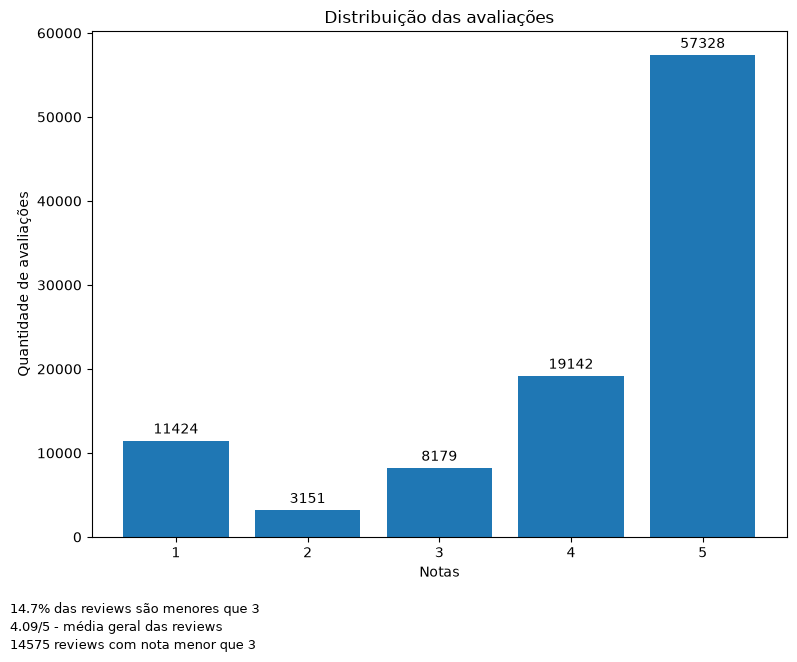

In [65]:
order_reviews.loc[(order_reviews['review_score'].isnull())] # checando se não existem valores nulos no campo de review_score 

order_reviews_menor_q_3 = order_reviews.loc[order_reviews['review_score'] < 3]
distribuicao_order_reviews_menor_q_3 =(
    order_reviews_menor_q_3.groupby('review_score')
    .agg(
        qtd=('review_score','count')
    )
)
media_order_review_menor_que_3 = len(order_reviews.query("review_score <  3")) / len(order_reviews) * 100
media_order_reviews_geral = float(order_reviews["review_score"].mean())

condicao = (
    (order_reviews["review_score"] < 3)
    & order_reviews["review_comment_message"].notna()
    & order_reviews["review_comment_message"].str.strip().ne("")
)

order_reviews_complaints = pd.DataFrame(order_reviews.loc[condicao])
order_reviews_complaints
order_reviews_complaints = order_reviews_complaints.drop_duplicates()
order_reviews_complaints.to_csv("created-tables/olist_order_reviews_complaints.csv")

distribuicao_order_reviews_menor_q_3

# Organizando as notas:
notas = order_reviews["review_score"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(notas.index, notas.values)
ax.bar_label(bars, padding=3, fmt="%.0f")
ax.set_title("Distribuição das avaliações")
ax.set_xlabel("Notas")
ax.set_ylabel("Quantidade de avaliações")
ax.set_xticks([1, 2, 3, 4, 5])
plt.figtext(0.01, -0.03, f"{media_order_review_menor_que_3:.1f}% das reviews são menores que 3", fontsize=9, color="black")
plt.figtext(0.01, -0.06, f"{media_order_reviews_geral:.2f}/5 - média geral das reviews", fontsize=9, color="black")
plt.figtext(0.01, -0.09, f"{len(order_reviews_menor_q_3)} reviews com nota menor que 3", fontsize=9, color="black")
plt.tight_layout()
plt.show()

Gerando um novo csv com os dados limpos que precisamos da tabela de reviews

In [66]:
order_reviews_complaints_full_data = (
    order_reviews_complaints[['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']]
    .merge(
        order_itens[['order_id','order_item_id','product_id','seller_id','price','freight_value']],
        on='order_id',
        how='left'
    ).merge(
        sellers[['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']],
        on='seller_id',
        how='left'
    ).merge(
        products[['product_id','product_category_name']],
        on='product_id',
        how='left'
    ).merge(
        order_payments,
        on='order_id',
        how='left'
    ).merge(
        orders[['order_id','order_status','order_purchase_timestamp','order_delivered_customer_date','order_estimated_delivery_date']],
        on='order_id',
        how='left',
    )
)

order_reviews_complaints_full_data = order_reviews_complaints_full_data.drop_duplicates()
order_reviews_complaints_full_data['seller_zip_code_prefix'] = order_reviews_complaints_full_data['seller_zip_code_prefix'].astype(str).str.strip()  
order_reviews_complaints_full_data['order_item_id'] = order_reviews_complaints_full_data['order_item_id'].astype('Int64')
order_reviews_complaints_full_data['payment_sequential'] = order_reviews_complaints_full_data['payment_sequential'].astype('Int64')
order_reviews_complaints_full_data['payment_installments'] = order_reviews_complaints_full_data['payment_installments'].astype('Int64')
order_reviews_complaints_full_data.dropna(how="all")

order_reviews_complaints_full_data.shape
order_reviews_complaints_full_data.to_csv("created-tables/order_review_complaints_full_data.csv")


Gerando uma nova tabela unindo dados de outras para uma melhor análise

In [67]:
#  !!! PROBLEMA: Estou encontrando muitas reviews e orders repetidas.
#  !!! RESOLVIDO: Esses valores eram de ordens com mais de 1 item por order.
#  Isso também justifica o preço algumas vezes ser maior que a soma do price e freight_value não dar o payment_value (que é a soma de todos os produtos da order + freight value) do produto

# pd.unique(order_reviews_complaints_full_data['review_id'])
order_reviews_complaints_analise_repetidos = order_reviews_complaints_full_data[
    [
        'review_id',
        'order_id',
        'price',
        'freight_value',
        'payment_value',
        'payment_type',
        'review_comment_message',
        'review_score',
        'order_purchase_timestamp',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
].dropna(subset='price')
order_reviews_complaints_analise_repetidos.to_csv('created-tables//order_reviews_complaints_analise_repetidos.csv')

order_reviews_complaints_analise_nao_repetidos = order_reviews_complaints_analise_repetidos.dropna(subset="order_delivered_customer_date")
# order_reviews_complaints_analise_nao_repetidos.to_csv('created-tables/order_reviews_complaints_analise_nao_repetidos.csv')
order_reviews_complaints_analise_nao_repetidos

,review_id,order_id,price,freight_value,payment_value,payment_type,review_comment_message,review_score,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
0,9314d6f9799f5bfba510cc7bcd468c01,0dacf04c5ad59fd5a0cc1faa07c34e39,166.99,21.66,188.65,credit_card,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E...",2,2017-12-19 13:14:37,2018-02-21 01:25:41,2018-01-17 00:00:00
2,2c5e27fc178bde7ac173c9c62c31b070,0ce9a24111d850192a933fcaab6fbad3,159.90,28.50,188.40,credit_card,Não gostei ! Comprei gato por lebre,1,2017-11-24 01:40:48,2017-12-13 00:28:44,2017-12-19 00:00:00
3,58044bca115705a48fe0e00a21390c54,68e55ca79d04a79f20d4bfc0146f4b66,137.00,17.67,154.67,credit_card,Sempre compro pela Internet e a entrega ocorre...,1,2018-03-16 12:51:35,2018-04-11 02:12:46,2018-04-06 00:00:00
4,9fd59cd04b42f600df9f25e54082a8d1,3c314f50bc654f3c4e317b055681dff9,59.00,31.70,296.89,credit_card,Nada de chegar o meu pedido.,1,2017-03-16 14:36:05,2017-04-24 09:18:11,2017-04-19 00:00:00
5,9fd59cd04b42f600df9f25e54082a8d1,3c314f50bc654f3c4e317b055681dff9,85.00,30.48,296.89,credit_card,Nada de chegar o meu pedido.,1,2017-03-16 14:36:05,2017-04-24 09:18:11,2017-04-19 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...
14925,9ed2a6bc2282fd2b0105055631afa57f,a7db1b7bfec5e83a8fd33625e99f0d15,129.90,25.75,466.95,credit_card,Ate hoje dia 21/10/2017 o pedido não foi entre...,1,2017-10-11 12:08:11,2017-10-20 14:44:33,2017-11-07 00:00:00
14927,3450ec3bbabeb09a08b00fc72da87a30,c46f950813dd2dd9bab4188dceb83175,899.90,40.00,939.90,credit_card,Boa tarde. \r\nNão recebo todos os produtos fa...,1,2017-12-02 19:55:21,2017-12-07 14:22:39,2018-01-09 00:00:00
14928,2ee221b28e5b6fceffac59487ed39348,f2d12dd37eaef72ed7b1186b2edefbcd,48.90,7.87,56.77,credit_card,Foto muito diferente principalmente a graninha...,2,2018-03-25 18:01:37,2018-03-27 13:48:59,2018-04-06 00:00:00
14929,5085bc489aa6b58a29c4f922d59ff826,18ed848509774f56cc8c1c0a1903ad7f,49.99,15.10,65.09,credit_card,Tive um problema na entrega em que o correio c...,2,2018-02-05 13:13:28,2018-02-20 01:15:50,2018-03-07 00:00:00


Porcentagem de entregas dentro do prazo

In [68]:
# percebi que os pedidos repetidos eram mais produtos na msm order e por isso serão desconsiderados para analise
porcentagem_de_entrega_dentro_do_tempo_notas_ruins = float((order_reviews_complaints_analise_nao_repetidos['order_delivered_customer_date'] < order_reviews_complaints_analise_nao_repetidos['order_estimated_delivery_date']).mean() * 100)

order_reviews_complaints_full_data_all = (
    order_reviews[['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']]
    .merge(
        order_itens[['order_id','order_item_id','product_id','seller_id','price','freight_value']],
        on='order_id',
        how='left'
    ).merge(
        sellers[['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']],
        on='seller_id',
        how='left'
    ).merge(
        products[['product_id','product_category_name']],
        on='product_id',
        how='left'
    ).merge(
        order_payments,
        on='order_id',
        how='left'
    ).merge(
        orders[['order_id','order_status','order_purchase_timestamp','order_delivered_customer_date','order_estimated_delivery_date']],
        on='order_id',
        how='left',
    )
)
order_reviews_complaints_full_data_all['seller_zip_code_prefix'] = order_reviews_complaints_full_data_all['seller_zip_code_prefix'].astype(str).str.strip()  
order_reviews_complaints_full_data_all['order_item_id'] = order_reviews_complaints_full_data_all['order_item_id'].astype('Int64')
order_reviews_complaints_full_data_all['payment_sequential'] = order_reviews_complaints_full_data_all['payment_sequential'].astype('Int64')
order_reviews_complaints_full_data_all['payment_installments'] = order_reviews_complaints_full_data_all['payment_installments'].astype('Int64')
order_reviews_complaints_full_data_all = order_reviews_complaints_full_data_all.dropna(subset="order_delivered_customer_date")
order_reviews_complaints_full_data_all.shape

order_reviews_complaints_full_data_all.to_csv("created-tables/all_order_reviews_full_data.csv")

porcentagem_de_entrega_dentro_do_tempo_notas_boas = float((order_reviews_complaints_full_data_all['order_delivered_customer_date'] < order_reviews_complaints_full_data_all['order_estimated_delivery_date']).mean() * 100)

condicao1 = (
    (order_reviews_complaints_full_data_all["order_delivered_customer_date"] < order_reviews_complaints_full_data_all["order_estimated_delivery_date"])
    & (order_reviews_complaints_full_data_all['review_score'] < 3)
)
order_review_complaints_entrega_atrasada = (
    order_reviews_complaints_full_data_all
    .loc[condicao1]
    .dropna(subset=['price'])
    .copy()
)

order_review_complaints_entrega_atrasada.to_csv("created-tables/order_review_complaints_entrega_atrasada.csv")
print(f"notas ruins: {porcentagem_de_entrega_dentro_do_tempo_notas_ruins:.2f} \nnotas boas: {porcentagem_de_entrega_dentro_do_tempo_notas_boas:.2f}")
order_reviews_complaints_full_data_all.shape

notas ruins: 74.28 
notas boas: 92.28


(114861, 24)

A partir de agora estaremos analisando apenas a order_review_complaints_entrega_atrasada.csv <br>Ela contém os dados necessários juntos para essa análise

In [69]:
order_review_complaints_entrega_atrasada

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,order_item_id,product_id,seller_id,...,seller_state,product_category_name,payment_sequential,payment_type,payment_installments,payment_value,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
6,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,NaN,NaN,2018-04-13 00:00:00,2018-04-16 00:39:37,1,c45d02cc82cd779835094de9b29272cb,da8622b14eb17ae2831f4ac5b9dab84a,...,SP,cama_mesa_banho,1,credit_card,1,462.70,delivered,2018-04-06 22:18:54,2018-04-12 17:17:53,2018-05-03 00:00:00
7,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,NaN,NaN,2018-04-13 00:00:00,2018-04-16 00:39:37,2,c45d02cc82cd779835094de9b29272cb,da8622b14eb17ae2831f4ac5b9dab84a,...,SP,cama_mesa_banho,1,credit_card,1,462.70,delivered,2018-04-06 22:18:54,2018-04-12 17:17:53,2018-05-03 00:00:00
8,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,NaN,NaN,2018-04-13 00:00:00,2018-04-16 00:39:37,3,4e3550b4ebca5e32ccc3d32b3470e31f,41ab63a91b8b264e8c8780368bf1dd5b,...,MG,cama_mesa_banho,1,credit_card,1,462.70,delivered,2018-04-06 22:18:54,2018-04-12 17:17:53,2018-05-03 00:00:00
9,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,NaN,NaN,2018-04-13 00:00:00,2018-04-16 00:39:37,4,c45d02cc82cd779835094de9b29272cb,da8622b14eb17ae2831f4ac5b9dab84a,...,SP,cama_mesa_banho,1,credit_card,1,462.70,delivered,2018-04-06 22:18:54,2018-04-12 17:17:53,2018-05-03 00:00:00
40,2c5e27fc178bde7ac173c9c62c31b070,0ce9a24111d850192a933fcaab6fbad3,1,NaN,Não gostei ! Comprei gato por lebre,2017-12-13 00:00:00,2017-12-16 07:14:07,1,948c22764c5080442c29a9c3da89b40f,54965bbe3e4f07ae045b90b0b8541f52,...,PR,cama_mesa_banho,1,credit_card,4,188.40,delivered,2017-11-24 01:40:48,2017-12-13 00:28:44,2017-12-19 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118080,3450ec3bbabeb09a08b00fc72da87a30,c46f950813dd2dd9bab4188dceb83175,1,NaN,Boa tarde. \r\nNão recebo todos os produtos fa...,2017-12-08 00:00:00,2017-12-08 19:07:00,1,3150c2690393e7ea7c2b3acf2479ec8c,ff69aa92bb6b1bf9b8b7a51c2ed9cf8b,...,SP,bebes,1,credit_card,8,939.90,delivered,2017-12-02 19:55:21,2017-12-07 14:22:39,2018-01-09 00:00:00
118096,6cf47345d15e054dd6df872e929bdb27,54e6829fe81bc86cf88b12e6d07ea298,1,NaN,NaN,2017-06-08 00:00:00,2017-06-08 22:52:39,1,d8342ac8b27a03e8d25280c296dfa830,6d7f8d9d594e28796b6b3205b00f459c,...,PR,moveis_decoracao,1,credit_card,2,199.74,delivered,2017-05-19 16:02:15,2017-06-07 08:33:06,2017-06-12 00:00:00
118119,2ee221b28e5b6fceffac59487ed39348,f2d12dd37eaef72ed7b1186b2edefbcd,2,Foto enganosa,Foto muito diferente principalmente a graninha...,2018-03-28 00:00:00,2018-05-25 01:23:26,1,6adab229374835b551f6402e0dc53267,f8db351d8c4c4c22c6835c19a46f01b0,...,SP,pet_shop,1,credit_card,1,56.77,delivered,2018-03-25 18:01:37,2018-03-27 13:48:59,2018-04-06 00:00:00
118122,5085bc489aa6b58a29c4f922d59ff826,18ed848509774f56cc8c1c0a1903ad7f,2,NaN,Tive um problema na entrega em que o correio c...,2018-02-21 00:00:00,2018-02-23 11:43:12,1,309dd69eb83cea38c51709d62befe1a4,0b35c634521043bf4b47e21547b99ab5,...,PR,construcao_ferramentas_construcao,1,credit_card,1,65.09,delivered,2018-02-05 13:13:28,2018-02-20 01:15:50,2018-03-07 00:00:00
